# Mouse atlas: lineage annotation (stage 04)

Every cluster of the whole-tissue scVI clustering is assigned one lineage (or EXCLUDE); the lineage objects re-integrated in 04b are cut from these labels.

Clustering: `data/interim/latent_mouse.h5ad`, column `leiden_scVI_2.5`. Decisions: `resources/annotations/mouse_lineage.csv`, one
row per cluster with the markers that justify the label in `note`. Nothing in this
notebook assigns a label; it shows the evidence the table was decided from.

In [1]:
import warnings
from pathlib import Path

import anndata as ad
import numpy as np
import pandas as pd
import scanpy as sc

# Notebook kernels start in notebooks/annotation/, so the repo root is two levels up.
REPO = Path("../..").resolve()
if not (REPO / "resources/annotations").is_dir():
    raise FileNotFoundError(f"{REPO} is not the repository root")
SPECIES, LEVEL, RESOLUTION = "mouse", "lineage", "leiden_scVI_2.5"
OBJECT = REPO / "data/interim/latent_mouse.h5ad"
TABLE = REPO / "resources/annotations/mouse_lineage.csv"
PANEL = ['Pdgfra', 'Col1a1', 'Prl8a2', 'Cdh1', 'Pax8', 'Epcam', 'Ptprc', 'Pecam1', 'Flt1', 'Acta2', 'Myh11', 'Msln', 'Upk3b', 'Wt1']
sc.settings.set_figure_params(dpi=80, frameon=False)
pd.set_option("display.max_colwidth", 200)

## 1. The committed table

In [2]:
table = pd.read_csv(TABLE, dtype={"cluster": str})
table.set_index("cluster")

,label,n_cells,res,note
cluster,,,,
0,epithelial,3046.0,leiden_scVI_2.5,"Cdh1 0.73; Pax8 0.84; Epcam 0.50 | top vs lineage: Mecom 0.99, Itpr2 0.97, Plekhs1 0.96"
1,stromal,589.0,leiden_scVI_2.5,"Pdgfra 0.74; Col1a1 0.59; Prl8a2 0.00 | top vs lineage: Diaph3 0.87, Top2a 0.83, Map2 0.85"
2,EXCLUDE,NaN,leiden_scVI_2.5,"EXCLUDE: doublet score med 0.0, genes med 942, 0.05 co-express 2+ lineage panels (epithelial 0.08, perimetrium 0.07, endothelial 0.04)"
3,epithelial,2797.0,leiden_scVI_2.5,"Cdh1 0.69; Pax8 0.83; Epcam 0.37 | top vs lineage: Prkg1 0.99, Galntl6 0.97, Gmds 0.94"
4,EXCLUDE,NaN,leiden_scVI_2.5,"EXCLUDE: doublet score med 10.1, genes med 2590, 0.19 co-express 2+ lineage panels (endothelial 0.76, stromal 0.18, perimetrium 0.05)"
5,EXCLUDE,NaN,leiden_scVI_2.5,"EXCLUDE: doublet score med 0.3, genes med 1314, 0.03 co-express 2+ lineage panels (endothelial 0.32, stromal 0.02, perimetrium 0.02)"
6,stromal,3359.0,leiden_scVI_2.5,"Pdgfra 0.64; Col1a1 0.42; Prl8a2 0.00 | top vs lineage: Rxfp1 0.91, Gria4 0.89, Cdh11 0.94"
7,EXCLUDE,NaN,leiden_scVI_2.5,"EXCLUDE: doublet score med 0.7, genes med 1983, 0.20 co-express 2+ lineage panels (smc_mural 0.36, endothelial 0.27, stromal 0.09)"
8,smc,1769.0,leiden_scVI_2.5,"Acta2 0.64; Myh11 0.90; Tagln 0.38 | top vs lineage: Cacna1c 0.93, Dmd 0.84, Slc8a1 0.86"


## 2. The clustered object (must carry exactly the clusters in the table)

In [3]:
adata = ad.read_h5ad(OBJECT)
adata.obs["cluster"] = adata.obs[RESOLUTION].astype(str)
in_object, in_table = set(adata.obs["cluster"]), set(table["cluster"])
if in_object != in_table:
    raise ValueError(f"cluster sets differ: object-only {sorted(in_object - in_table)}, "
                     f"table-only {sorted(in_table - in_object)}")
labels = table.set_index("cluster")["label"]
adata.obs["label"] = adata.obs["cluster"].map(labels).astype("category")
print(adata.n_obs, "nuclei;", len(in_object), "clusters")
print(adata.obs["label"].value_counts().to_dict())

68069 nuclei; 38 clusters
{'stromal': 43197, 'EXCLUDE': 9715, 'epithelial': 6681, 'vascular': 3962, 'immune': 2091, 'smc': 1769, 'perimetrium': 654}


In [4]:
# Expression for the dot plot: CP10K log1p from raw counts.
counts = adata.layers["counts"] if "counts" in adata.layers else adata.X
expr = ad.AnnData(X=counts.copy(), obs=adata.obs[["cluster", "label"]].copy(),
                  var=adata.var[[]].copy())
sc.pp.normalize_total(expr, target_sum=1e4)
sc.pp.log1p(expr)
genes = [g for g in PANEL if g in expr.var_names]
missing = sorted(set(PANEL) - set(genes))
if missing:
    print("not in this object:", missing)

## 3. Marker dot plot by cluster

Dot size is the fraction of nuclei in which the gene is detected, colour the mean
log1p CP10K. Clusters are grouped by their label; EXCLUDE clusters are last.

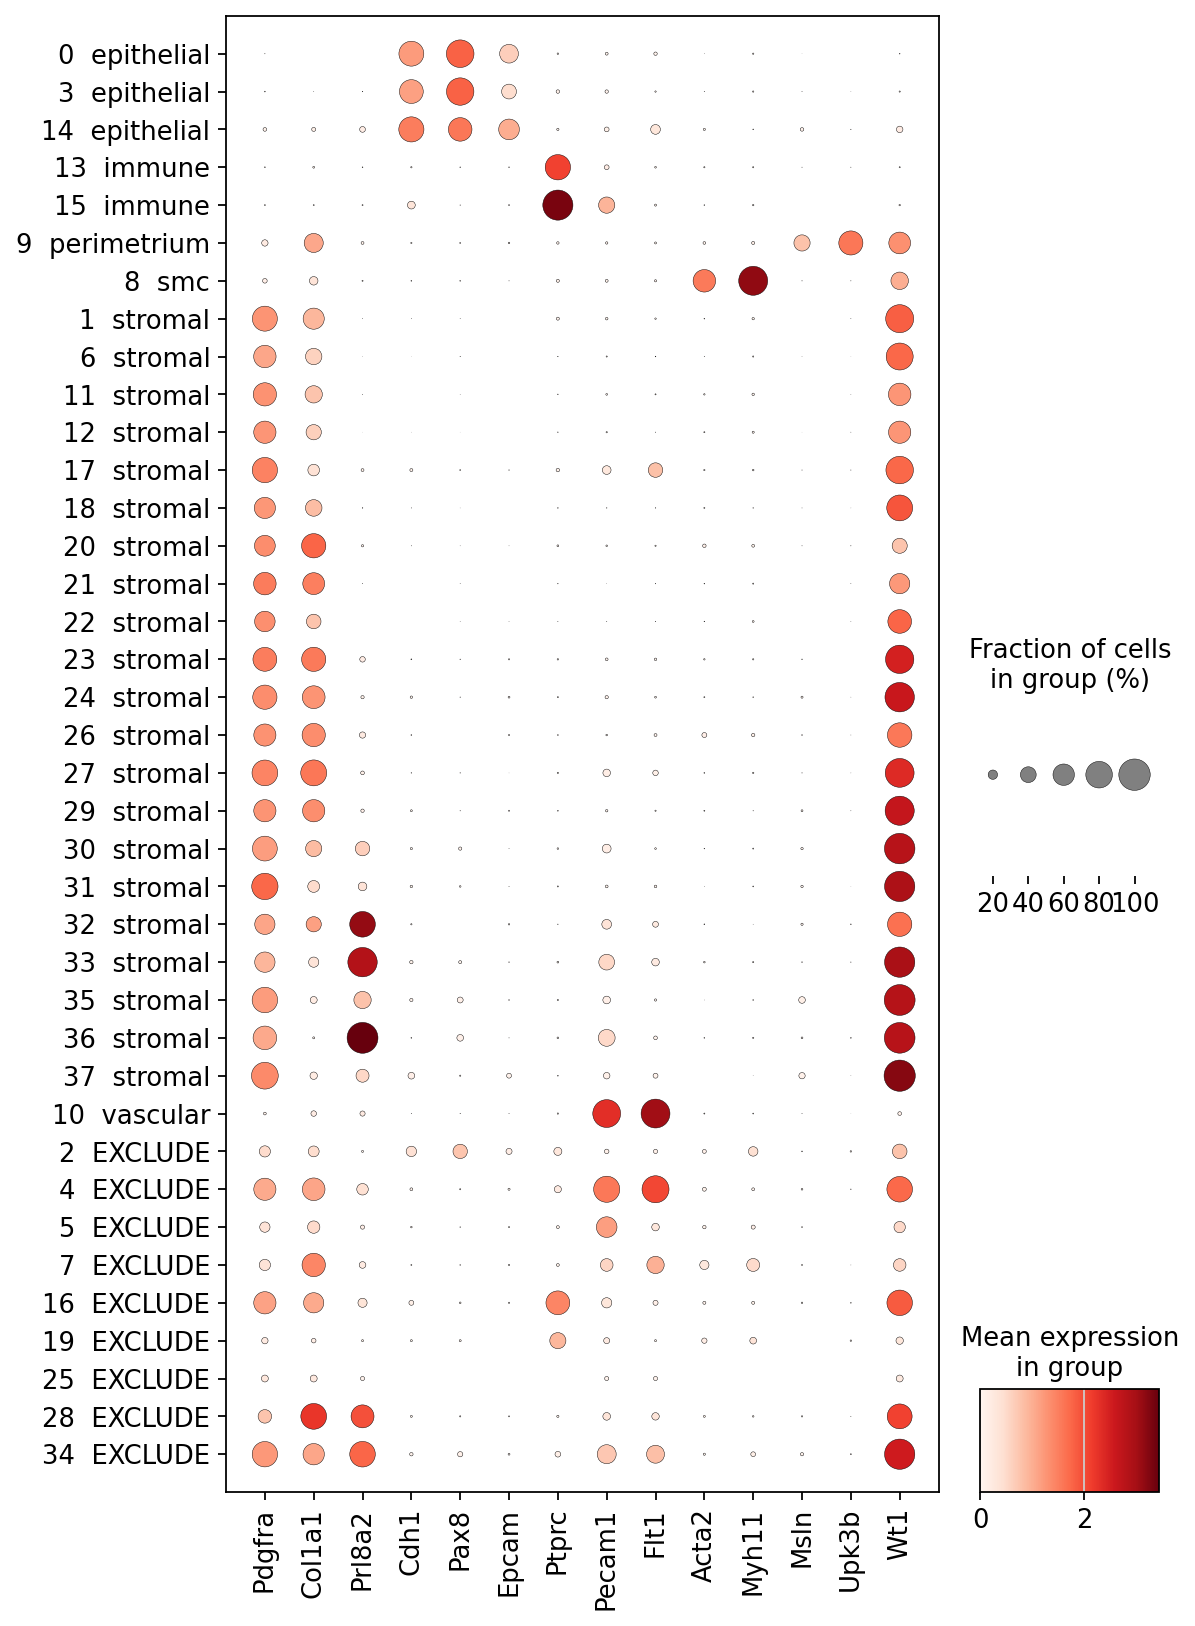

In [5]:
def sort_key(c):
    return (labels[c] == "EXCLUDE", labels[c], int(c) if c.isdigit() else c)

order = sorted(in_object, key=sort_key)
expr.obs["cluster_labelled"] = pd.Categorical(
    [f"{c}  {labels[c]}" for c in expr.obs["cluster"]],
    categories=[f"{c}  {labels[c]}" for c in order])
sc.pl.dotplot(expr, genes, groupby="cluster_labelled", standard_scale=None,
              figsize=(0.32 * len(genes) + 3, 0.28 * len(order) + 1.5))

## 4. QC per cluster

Median DoubletDetection score and genes per nucleus per cluster, with the lineage
median for reference. A high doublet score together with markers of another lineage
(section 6) is what an EXCLUDE call rests on; a moderate score alone is not
(cycling clusters score around 1 throughout this dataset).

In [6]:
qc_cols = [c for c in ("doubletdetection_doublet_score", "n_genes_by_counts",
                       "total_counts") if c in adata.obs]
qc = adata.obs.groupby("cluster", observed=True)[qc_cols].median().loc[order]
qc.insert(0, "n", adata.obs["cluster"].value_counts().loc[order])
qc.insert(1, "label", labels.loc[order])
qc.loc["lineage median"] = [adata.n_obs, ""] + list(adata.obs[qc_cols].median())
qc.round(2)

,n,label,doubletdetection_doublet_score,n_genes_by_counts,total_counts
cluster,,,,,
0,3046,epithelial,0.00,2531.0,5455.5
3,2797,epithelial,0.00,2510.0,5033.0
14,838,epithelial,1.07,2093.5,3891.0
13,1263,immune,0.00,982.0,1382.0
15,828,immune,0.00,1061.0,1510.0
9,654,perimetrium,0.39,1577.0,2393.0
8,1769,smc,0.01,1005.0,1624.0
1,589,stromal,0.93,2687.0,5253.0
6,3359,stromal,0.02,2241.0,4243.0


## 5. UMAP by cluster and by label

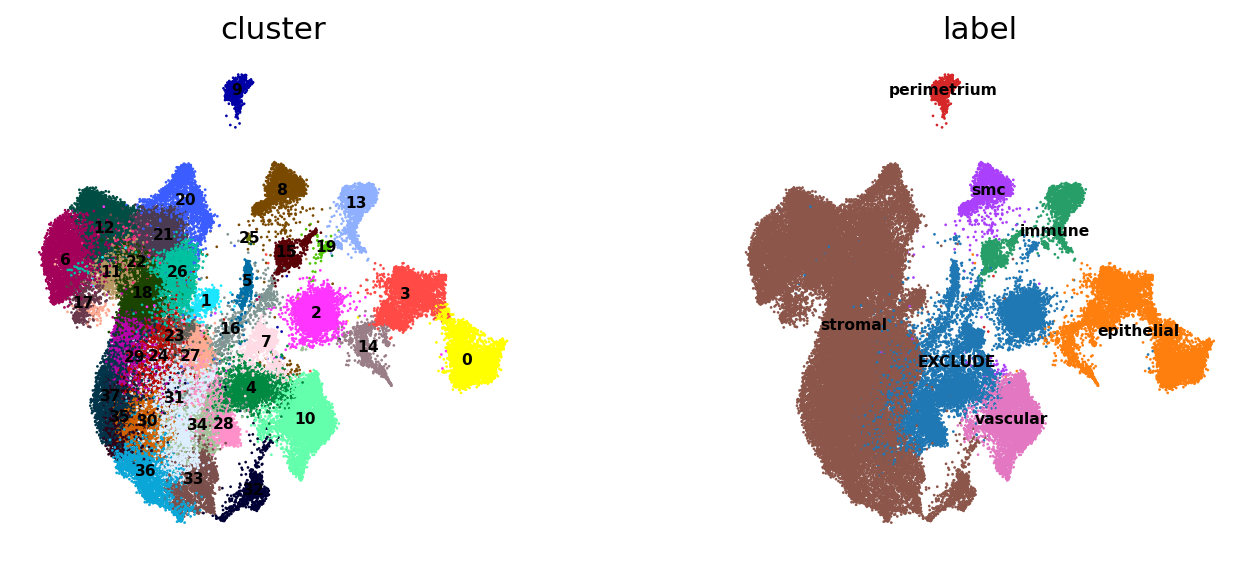

In [7]:
umap_key = next((k for k in ("X_umap_scVI", "X_umap") if k in adata.obsm), None)
if umap_key is None:
    latent_key = next(k for k in adata.obsm if "scVI" in k or "scvi" in k)
    sc.pp.neighbors(adata, use_rep=latent_key, n_neighbors=15, random_state=0)
    sc.tl.umap(adata, random_state=0)
    umap_key = "X_umap"
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    sc.pl.embedding(adata, basis=umap_key, color=["cluster", "label"], legend_loc="on data",
                    legend_fontsize=7, size=6, ncols=2, wspace=0.25)

## 6. EXCLUDE clusters

Detection of each lineage's markers inside the excluded clusters, next to the
lineage-wide detection; a cluster is excluded when it carries another lineage's
programme (doublets) or too little RNA to call.

In [8]:
excluded = [c for c in order if labels[c] == "EXCLUDE"]
if excluded:
    detected = pd.DataFrame(
        {c: np.asarray((expr[expr.obs["cluster"] == c, genes].X > 0).mean(0)).ravel()
         for c in excluded},
        index=genes)
    detected["lineage"] = np.asarray((expr[:, genes].X > 0).mean(0)).ravel()
    display(detected.round(2).T)
else:
    print("no EXCLUDE clusters in this table")

,Pdgfra,Col1a1,Prl8a2,Cdh1,Pax8,Epcam,Ptprc,Pecam1,Flt1,Acta2,Myh11,Msln,Upk3b,Wt1
2,0.25,0.24,0.03,0.23,0.35,0.11,0.16,0.08,0.07,0.06,0.20,0.01,0.02,0.36
4,0.63,0.64,0.26,0.04,0.01,0.03,0.14,0.78,0.82,0.06,0.04,0.02,0.00,0.76
5,0.23,0.29,0.07,0.02,0.01,0.01,0.04,0.57,0.15,0.05,0.07,0.01,0.00,0.26
7,0.26,0.67,0.13,0.01,0.01,0.02,0.04,0.30,0.45,0.19,0.31,0.01,0.00,0.29
16,0.63,0.55,0.19,0.08,0.02,0.01,0.69,0.22,0.09,0.04,0.04,0.02,0.01,0.76
19,0.12,0.08,0.03,0.03,0.03,0.00,0.41,0.11,0.03,0.09,0.13,0.00,0.02,0.15
25,0.13,0.13,0.07,0.00,0.00,0.00,0.00,0.07,0.07,0.00,0.00,0.00,0.00,0.13
28,0.33,0.77,0.66,0.03,0.01,0.01,0.03,0.15,0.15,0.03,0.02,0.01,0.00,0.73
34,0.75,0.60,0.76,0.05,0.09,0.02,0.10,0.51,0.47,0.03,0.08,0.05,0.01,0.95
lineage,0.49,0.38,0.16,0.10,0.11,0.06,0.06,0.16,0.13,0.04,0.05,0.02,0.01,0.62
